In [1]:
import torch
import torchvision
import pyjuice as juice
import pyjuice.io
import pyjuice.nodes.distributions as dists
from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt
import json
import numpy as np

In [2]:
# Set device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:0


In [3]:
# STEP 1: Load and Preprocess MNIST Data (Digits 0 and 1 only)

print("="*80)
print("STEP 1: Loading MNIST Dataset (Digits 0 and 1)")
print("="*80)

# Load full MNIST dataset
train_dataset = torchvision.datasets.MNIST(root="./data", train=True, download=True)
test_dataset = torchvision.datasets.MNIST(root="./data", train=False, download=True)

# Extract only digits 0 and 1
def filter_digits(dataset, digits=[0, 1]):
    """Filter dataset to only include specified digits"""
    mask = sum([dataset.targets == d for d in digits]).bool()
    data = dataset.data[mask]
    targets = dataset.targets[mask]
    return data, targets

train_data, train_targets = filter_digits(train_dataset, [0, 1])
test_data, test_targets = filter_digits(test_dataset, [0, 1])

# Reshape to [num_samples, num_vars] - flatten 28x28 images to 784 features
train_data = train_data.reshape(-1, 28*28)
test_data = test_data.reshape(-1, 28*28)

print(f"Training samples: {train_data.shape[0]} (shape: {train_data.shape})")
print(f"Test samples: {test_data.shape[0]} (shape: {test_data.shape})")
print(f"Class 0 samples: {(train_targets == 0).sum().item()}")
print(f"Class 1 samples: {(train_targets == 1).sum().item()}")
print(f"Pixel value range: [{train_data.min().item()}, {train_data.max().item()}]")

STEP 1: Loading MNIST Dataset (Digits 0 and 1)


100%|██████████| 9.91M/9.91M [00:08<00:00, 1.15MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 142kB/s]
100%|██████████| 1.65M/1.65M [00:03<00:00, 482kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.68MB/s]

Training samples: 12665 (shape: torch.Size([12665, 784]))
Test samples: 2115 (shape: torch.Size([2115, 784]))
Class 0 samples: 5923
Class 1 samples: 6742
Pixel value range: [0, 255]



STEP 2: Binarizing MNIST (Grayscale → Binary)
Binary training data shape: torch.Size([12665, 784])
Binary test data shape: torch.Size([2115, 784])
Unique values: [0, 1]
Percentage of ink pixels: 17.28%


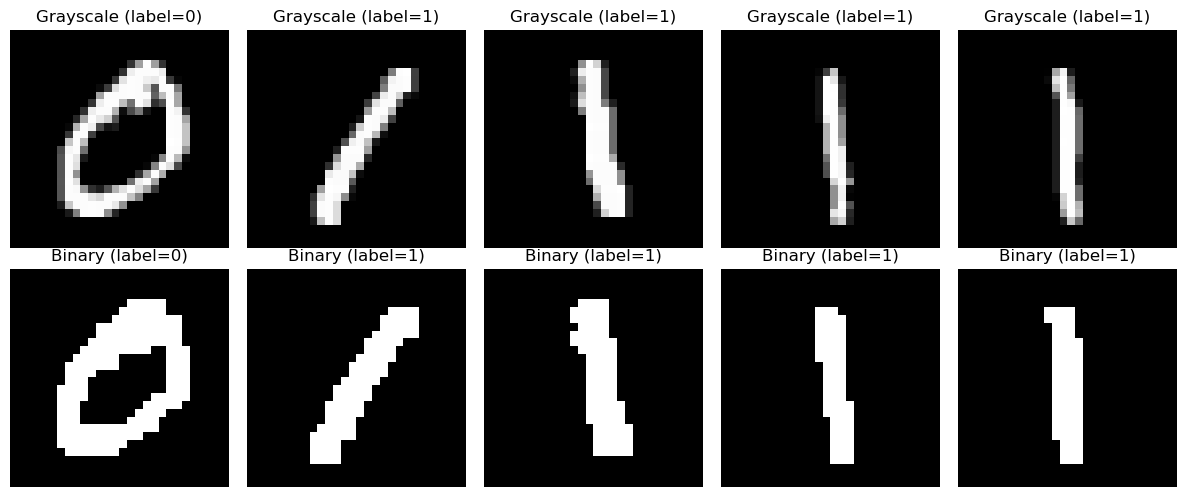

In [5]:
# STEP 2: Create Binary Version (256 categories → 2 categories)

print("\n" + "="*80)
print("STEP 2: Binarizing MNIST (Grayscale → Binary)")
print("="*80)

# Convert to binary: 0 = background (black), 1 = foreground (ink)
train_data_binary = (train_data > 0).long()
test_data_binary = (test_data > 0).long()

print(f"Binary training data shape: {train_data_binary.shape}")
print(f"Binary test data shape: {test_data_binary.shape}")
print(f"Unique values: {train_data_binary.unique().tolist()}")
print(f"Percentage of ink pixels: {(train_data_binary.sum() / train_data_binary.numel() * 100):.2f}%")

# Visualize the difference
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    # Original grayscale
    axes[0, i].imshow(train_data[i].reshape(28, 28), cmap='gray')
    axes[0, i].set_title(f"Grayscale (label={train_targets[i]})")
    axes[0, i].axis('off')

    # Binary
    axes[1, i].imshow(train_data_binary[i].reshape(28, 28), cmap='gray')
    axes[1, i].set_title(f"Binary (label={train_targets[i]})")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


STEP 3: Downsampling 28x28 → 14x14 (784 → 196 features)
Downsampled grayscale shape: torch.Size([12665, 196])
Downsampled binary shape: torch.Size([12665, 196])
Feature reduction: 784 → 196 (75% reduction)


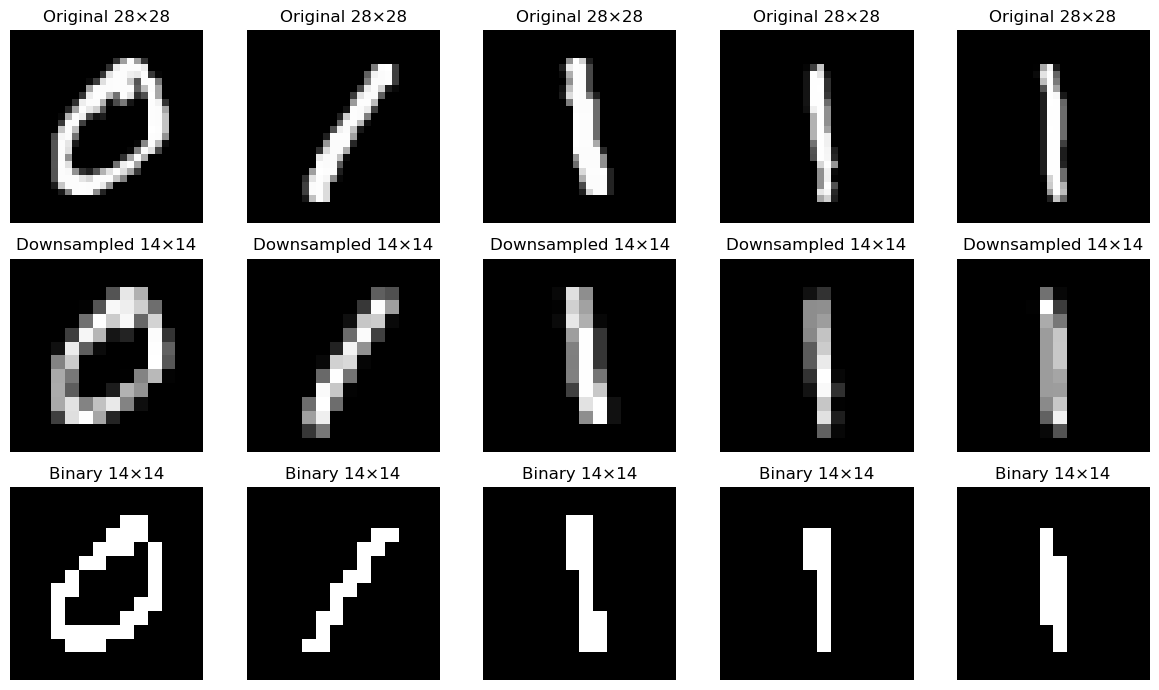

In [6]:
# STEP 3 (OPTIONAL): Downsample to Reduce Features (784 → 196)

print("\n" + "="*80)
print("STEP 3: Downsampling 28x28 → 14x14 (784 → 196 features)")
print("="*80)

import torch.nn.functional as F

def downsample_images(data, target_size=14):
    """Downsample images using average pooling"""
    # Reshape to [batch, 1, 28, 28]
    data_2d = data.reshape(-1, 1, 28, 28).float()

    # Average pooling 28x28 → 14x14
    downsampled = F.avg_pool2d(data_2d, kernel_size=2, stride=2)

    # Flatten back to [batch, 196]
    return downsampled.reshape(-1, target_size * target_size)

# Downsample grayscale version
train_data_small = downsample_images(train_data, target_size=14).long()
test_data_small = downsample_images(test_data, target_size=14).long()

# Downsample binary version
train_data_binary_small = ((train_data_small) > 128).long()
test_data_binary_small = ((test_data_small) > 128).long()

print(f"Downsampled grayscale shape: {train_data_small.shape}")
print(f"Downsampled binary shape: {train_data_binary_small.shape}")
print(f"Feature reduction: 784 → 196 (75% reduction)")

# Visualize downsampling
fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i in range(5):
    # Original 28x28
    axes[0, i].imshow(train_data[i].reshape(28, 28), cmap='gray')
    axes[0, i].set_title(f"Original 28×28")
    axes[0, i].axis('off')

    # Downsampled 14x14 (grayscale)
    axes[1, i].imshow(train_data_small[i].reshape(14, 14), cmap='gray')
    axes[1, i].set_title(f"Downsampled 14×14")
    axes[1, i].axis('off')

    # Downsampled 14x14 (binary)
    axes[2, i].imshow(train_data_binary_small[i].reshape(14, 14), cmap='gray')
    axes[2, i].set_title(f"Binary 14×14")
    axes[2, i].axis('off')

plt.tight_layout()
plt.show()

In [11]:
# save test data binary small
torch.save(test_data_binary_small, "examples/models/mnist_binary_small_0_vs_1/mnist_test_data_binary_small.pt")
# save test targets
torch.save(test_targets, "examples/models/mnist_binary_small_0_vs_1/test_targets.pt")

## Training

In [ ]:
# Build and Train PC on Binary Data

print("\n" + "="*80)
print("STEP 4: Building PC with Categorical Distribution (Binary)")
print("="*80)

# Choose which data to use
# Option 1: Full binary (784 features, 2 categories)
# data_train = train_data_binary
# data_test = test_data_binary
# num_features = 784
# img_size = 28

# Option 2: Downsampled binary (196 features, 2 categories)

num_features = 14 * 14 # 196
img_size = 14


# Separate data by class
num_classes = 2
train_data_small_0 = train_data_binary_small[train_targets == 0]
train_data_small_1 = train_data_binary_small[train_targets == 1]

print(f"\nTraining class-specific circuits...")
print(f"  Class 0: {len(train_data_small_0)} samples")
print(f"  Class 1: {len(train_data_small_1)} samples")



STEP 4: Building PC with Categorical Distribution (Binary)

Training class-specific circuits...
  Class 0: 5923 samples
  Class 1: 6742 samples


In [29]:
def create_dataloaders(data, targets=None, batch_size=512, drop_last=True):
    """Create DataLoader from data and targets"""
    if targets is not None:
        dataset = TensorDataset(data, targets)
    else:
        dataset = TensorDataset(data)

    loader = DataLoader(
        dataset=dataset,
        batch_size=batch_size,
        shuffle=True,
        drop_last=drop_last
    )
    return loader

In [30]:
def compile_hclt_circuit(data, num_latents, device):
    """Build and compile HCLT circuit with Categorical distribution"""
    ns = juice.structures.HCLT(
        data.float().to(device),
        num_latents=num_latents,
        input_dist=dists.Categorical(num_cats=2)  # Binary as 2 categories
    )
    pc = juice.compile(ns)
    pc.to(device)
    return pc

In [31]:
train_pc_loader = create_dataloaders(train_data_binary_small, train_targets, batch_size=512, drop_last=True)
test_pc_loader = create_dataloaders(test_data_binary_small, test_targets, batch_size=512, drop_last=False)

train_pc_0_loader = create_dataloaders(train_data_small_0, batch_size=512, drop_last=True)
train_pc_1_loader = create_dataloaders(train_data_small_1, batch_size=512, drop_last=True)

In [32]:
pc = compile_hclt_circuit(train_data_binary_small, num_latents=64, device=device)
print(f"  Parameters: {sum(p.numel() for p in pc.parameters()):,}")
pc_0 = compile_hclt_circuit(train_data_small_0, num_latents=32, device=device)
print(f"  Parameters: {sum(p.numel() for p in pc_0.parameters()):,}")
pc_1 = compile_hclt_circuit(train_data_small_1, num_latents=32, device=device)
print(f"  Parameters: {sum(p.numel() for p in pc_1.parameters()):,}")

Compiling 11 TensorCircuit layers...


100%|██████████| 11/11 [00:00<00:00, 164.02it/s]

  Parameters: 369,552


Compiling 14 TensorCircuit layers...


100%|██████████| 14/14 [00:00<00:00, 181.63it/s]

  Parameters: 106,899


Compiling 12 TensorCircuit layers...


100%|██████████| 12/12 [00:00<00:00, 173.40it/s]

  Parameters: 80,938


In [33]:
# STEP 5: Train the Circuit

# Setup optimizer
optimizer = juice.optim.CircuitOptimizer(
    pc,
    lr=0.1,
    pseudocount=0.01,  # Lower for binary (only 2 values)
    method="EM"
)
# Create optimizer for pc_0
optimizer_0 = juice.optim.CircuitOptimizer(pc_0, lr=0.1, pseudocount=0.01, method="EM")

# Create optimizer for pc_1
optimizer_1 = juice.optim.CircuitOptimizer(pc_1, lr=0.1, pseudocount=0.01, method="EM")

num_epochs = 20

def train_pc(pc, train_loader, test_loader, optimizer, device, num_epochs, evaluate=True):
    """Train the probabilistic circuit"""

    # CUDA graph warmup
    if device.type == "cuda":
        for batch in train_loader:
            x = batch[0].to(device)
            lls = pc(x, record_cudagraph=True)
            lls.mean().backward()
            break

    # Training loop
    print(f"\nTraining for {num_epochs} epochs...")
    print(f"{'Epoch':<8} {'Train LL':<12} {'Test LL':<12}")
    print("-" * 35)

    for epoch in range(1, num_epochs + 1):
        pc.train()
        train_ll = 0.0

        for batch in train_loader:
            x = batch[0].to(device)
            optimizer.zero_grad()
            lls = pc(x)
            lls.mean().backward()
            train_ll += lls.mean().detach().cpu().item()
            optimizer.step()

        train_ll /= len(train_loader)

        # Evaluate every 5 epochs
        if evaluate and (epoch % 5 == 0 or epoch == 1):
            pc.eval()
            test_ll = 0.0
            with torch.no_grad():
                for batch in test_loader:
                    x = batch[0].to(device)
                    lls = pc(x)
                    test_ll += lls.mean().detach().cpu().item()
            test_ll /= len(test_loader)
            print(f"{epoch:<8} {train_ll:<12.2f} {test_ll:<12.2f}")
        else:
            print(f"{epoch:<8} {train_ll:<12.2f} {'---':<12}")

    print("\nTraining complete!")

In [34]:
train_pc(pc, train_pc_loader, test_pc_loader, optimizer, device, num_epochs)


Training for 20 epochs...
Epoch    Train LL     Test LL     
-----------------------------------
1        -66.17       -37.31      
2        -32.62       ---         
3        -29.17       ---         
4        -28.12       ---         
5        -27.31       -26.84      
6        -26.63       ---         
7        -25.96       ---         
8        -25.39       ---         
9        -24.91       ---         
10       -24.54       -24.31      
11       -24.19       ---         
12       -23.88       ---         
13       -23.58       ---         
14       -23.30       ---         
15       -23.06       -22.91      
16       -22.85       ---         
17       -22.64       ---         
18       -22.45       ---         
19       -22.28       ---         
20       -22.11       -22.06      

Training complete!


In [36]:
train_pc(pc_0, train_pc_0_loader, None, optimizer_0, device, num_epochs, evaluate=False)
train_pc(pc_1, train_pc_1_loader, None, optimizer_1, device, num_epochs, evaluate=False)


Training for 20 epochs...
Epoch    Train LL     Test LL     
-----------------------------------
1        -89.56       ---         
2        -52.18       ---         
3        -41.80       ---         
4        -37.73       ---         
5        -36.01       ---         
6        -35.13       ---         
7        -34.63       ---         
8        -34.18       ---         
9        -33.77       ---         
10       -33.42       ---         
11       -33.10       ---         
12       -32.86       ---         
13       -32.65       ---         
14       -32.41       ---         
15       -32.22       ---         
16       -32.01       ---         
17       -31.86       ---         
18       -31.69       ---         
19       -31.56       ---         
20       -31.35       ---         

Training complete!

Training for 20 epochs...
Epoch    Train LL     Test LL     
-----------------------------------
1        -76.05       ---         
2        -28.18       ---         
3        -18.1

In [37]:
# Save and Load Models

# Save the model
print("\nSaving model...")
juice.io.save("./examples/models/mnist_binary_small_0_vs_1/mnist_binary_model.jpc", pc)
juice.io.save("./examples/models/mnist_binary_small_0_vs_1/class_0.jpc", pc_0)
juice.io.save("./examples/models/mnist_binary_small_0_vs_1/class_1.jpc", pc_1)
print("Model saved to ./examples/models/mnist_binary_small_0_vs_1/")


Saving model...
Model saved to ./examples/models/mnist_binary_small_0_vs_1/


In [95]:
# save metadata
metadata = {
    "img_size": img_size,
    "num_features": num_features,
    "num_classes": num_classes,
    "num_samples": len(train_data_binary_small),
    "num_samples_class_0": (train_targets == 0).sum().item(),
    "num_samples_class_1": (train_targets == 1).sum().item(),
    "prior_k0": (train_targets == 0).sum().item() / len(train_data_binary_small),
    "prior_k1": (train_targets == 1).sum().item() / len(train_data_binary_small)
}
with open("./examples/models/mnist_binary_small_0_vs_1/mnist_binary_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)
print("Metadata saved to ./examples/models/mnist_binary_small_0_vs_1/mnist_binary_metadata.json")

Metadata saved to ./examples/models/mnist_binary_small_0_vs_1/mnist_binary_metadata.json


## Load models

In [5]:
# load metadata
with open(
    "models/mnist_binary_small_0_vs_1/mnist_binary_metadata.json",
    "r",
) as f:
    metadata_loaded = json.load(f)
print("Loaded metadata:")
print(json.dumps(metadata_loaded, indent=4))

Loaded metadata:
{
    "img_size": 14,
    "num_features": 196,
    "num_classes": 2,
    "num_samples": 12665,
    "num_samples_class_0": 5923,
    "num_samples_class_1": 6742,
    "prior_k0": 0.46766679826292934,
    "prior_k1": 0.5323332017370707
}


In [7]:
# Load the model back
print("\nLoading model from disk...")
loaded_ns = juice.io.load(
    "models/mnist_binary_small_0_vs_1/mnist_binary_model.jpc"
)  # Returns circuit nodes

pc = juice.compile(loaded_ns)  # Compile before using
pc.to(device)

loaded_ns_0 = juice.io.load(
    "models/mnist_binary_small_0_vs_1/class_0.jpc"
)
pc_0 = juice.compile(loaded_ns_0)
pc_0.to(device)

loaded_ns_1 = juice.io.load(
    "models/mnist_binary_small_0_vs_1/class_1.jpc"
)
pc_1 = juice.compile(loaded_ns_1)
pc_1.to(device)


Loading model from disk...
Compiling 11 TensorCircuit layers...


100%|██████████| 11/11 [00:01<00:00,  5.78it/s]


Compiling 14 TensorCircuit layers...


100%|██████████| 14/14 [00:00<00:00, 101.61it/s]


Compiling 12 TensorCircuit layers...


100%|██████████| 12/12 [00:00<00:00, 95.49it/s]


TensorCircuit(
  (input_layer_group): LayerGroup(
    (layer_0): InputLayer()
  )
  (prod_layer_0): LayerGroup(
    (layer_0): ProdLayer(
      (partitioned_nids): FastParamList(
          (0): Parameter containing: [torch.int64 of size 15 (cuda:0)]
          (1): Parameter containing: [torch.int64 of size 4 (cuda:0)]
      )
      (partitioned_cids): FastParamList(
          (0): Parameter containing: [torch.int64 of size 15x2 (cuda:0)]
          (1): Parameter containing: [torch.int64 of size 4x4 (cuda:0)]
      )
      (partitioned_u_cids): FastParamList(  (0): Parameter containing: [torch.int64 of size 43 (cuda:0)])
      (partitioned_parids): FastParamList(  (0): Parameter containing: [torch.int64 of size 43x1 (cuda:0)])
    )
  )
  (sum_layer_0): LayerGroup(
    (layer_0): SumLayer(
      (partitioned_nids): FastParamList(  (0): Parameter containing: [torch.int64 of size 19 (cuda:0)])
      (partitioned_cids): FastParamList(  (0): Parameter containing: [torch.int64 of size 19x32 

In [9]:
loaded_ns_0 = juice.io.load(
    "models/mnist_binary_small_0_vs_1/class_0.jpc"
)
pc_0_not_device = juice.compile(loaded_ns_0)

Compiling 14 TensorCircuit layers...


100%|██████████| 14/14 [00:00<00:00, 44.99it/s]


In [10]:
# exploring shape of the PC
for ns in loaded_ns_0:
    print(type(ns).__name__)
    print(f"  num_node_blocks : {ns.num_node_blocks}")
    print(f"  block_size      : {ns.block_size}")
    print(f"  num_nodes       : {ns.num_nodes}")

    if ns.is_input():
        print(f"  scope           : {ns.scope}")
        print(f"  _params shape   : {ns._params.shape}")
        print(f"  _params sample  : {ns._params.flatten()[:4]}")

    if ns.is_prod() or ns.is_sum():
        print(f"  num_chs         : {len(ns.chs)}")
        print(f"  edge_ids shape  : {ns.edge_ids.shape}")
        print(f"  edge_ids sample : {ns.edge_ids[:3]}")

    if ns.is_sum():
        print(f"  _params shape   : {ns._params.shape}")
        print(f"  _params sample  : {ns._params.flatten()[:4]}")

    print()

InputNodes
  num_node_blocks : 1
  block_size      : 32
  num_nodes       : 32
  scope           : BitSet([58])
  _params shape   : torch.Size([64])
  _params sample  : tensor([9.9973e-01, 2.7449e-04, 9.9934e-01, 6.6237e-04])

InputNodes
  num_node_blocks : 1
  block_size      : 32
  num_nodes       : 32
  scope           : BitSet([72])
  _params shape   : torch.Size([64])
  _params sample  : tensor([9.9972e-01, 2.7530e-04, 9.9934e-01, 6.5902e-04])

ProdNodes
  num_node_blocks : 1
  block_size      : 32
  num_nodes       : 32
  num_chs         : 2
  edge_ids shape  : torch.Size([1, 2])
  edge_ids sample : tensor([[0, 0]])

SumNodes
  num_node_blocks : 1
  block_size      : 32
  num_nodes       : 32
  num_chs         : 1
  edge_ids shape  : torch.Size([2, 1])
  edge_ids sample : tensor([[0],
        [0]])
  _params shape   : torch.Size([1, 32, 32])
  _params sample  : tensor([0.0561, 0.0132, 0.0273, 0.0745])

InputNodes
  num_node_blocks : 1
  block_size      : 32
  num_nodes       : 32

In [11]:
print(pc.root_ns.chs[0].block_size)

64


In [12]:
# Verificar el nodo de entrada más simple
for ns in pc.root_ns:
    if ns.is_input():
        print("block_size:", ns.block_size)
        print("_params shape:", ns._params.shape)
        # Esperamos [128] = 2 * 64
        break
    if ns.is_prod():
        print("arity:", len(ns.chs))

block_size: 64
_params shape: torch.Size([128])


In [13]:
# Setup
pc_per_class = {0: pc_0, 1: pc_1}
priors = {
    0: metadata_loaded["prior_k0"],
    1: metadata_loaded["prior_k1"]
}
num_features = metadata_loaded["num_features"]
img_size = metadata_loaded["img_size"]


In [14]:
# define a function to create a random mask
def create_random_mask(batch_size, num_features, observed_ratio=0.5):
    mask = torch.rand(batch_size, num_features) < observed_ratio
    return mask


In [20]:
# load test data and targets
test_data_binary_small = torch.load("models/mnist_binary_small_0_vs_1/mnist_test_data_binary_small.pt")
test_targets = torch.load("models/mnist_binary_small_0_vs_1/test_targets.pt")

### Inference

In [16]:
# Query Functions for Split PCs

def marginal_query_split_pcs(pc_per_class, priors, data, observed_mask,
                              class_value=None):
    """
    Marginal query with split PCs handling different cases

    Args:
        pc_per_class: Dict {class_id: pc_model}
        priors: Dict {class_id: prior_probability}
        data: Input data [batch, features]
        observed_mask: Boolean mask [batch, features] (True = observed)
        class_value: None for P(x), int for P(x, k)

    Returns:
        log_prob: Log probability based on query type [batch]

    Query types:
        1. class_value=None → P(x) - marginalize over classes
        2. class_value=k → P(x, k) - joint probability
    """

    with torch.no_grad():
        # Convert observed_mask to missing_mask for PyJuice API
        missing_mask = ~observed_mask

        if class_value is None:
            # Case 1: P(x) = Σ_k P(x, k) = Σ_k P(x|k) × P(k)
            # Marginalize over ALL classes

            log_probs = []
            for k, pc in pc_per_class.items():
                # P(x, k) = P(x|k) × P(k)
                log_p_x_given_k = juice.queries.marginal(pc, data, missing_mask).squeeze()
                log_p_x_and_k = log_p_x_given_k + torch.log(torch.tensor(priors[k]).to(data.device))
                log_probs.append(log_p_x_and_k)

            # P(x) = Σ_k P(x, k)
            log_p_x = torch.logsumexp(torch.stack(log_probs, dim=0), dim=0)
            return log_p_x

        else:
            # Case 2: P(x, k) = P(x|k) × P(k)
            pc = pc_per_class[class_value]

            # P(x | k) - conditional on class
            log_p_x_given_k = juice.queries.marginal(pc, data, missing_mask).squeeze()

            log_p_x_and_k = log_p_x_given_k + torch.log(torch.tensor(priors[class_value]).to(data.device))
            return log_p_x_and_k


def conditional_query_split_pcs(pc_per_class, priors, data, target_mask, observed_mask,
                                class_value=None, class_as_target=False):
    """
    Classical conditional query: P(targets | observed) = P(targets, observed) / P(observed)
    Using ratio of marginals approach

    Args:
        pc_per_class: Dict {class_id: pc_model}
        priors: Dict {class_id: prior_probability}
        data: Input data [batch, features]
        target_mask: Boolean mask [batch, features] (True = target variables)
        observed_mask: Boolean mask [batch, features] (True = observed variables)
        class_value:
            - If class_as_target=False: None for marginalizing, int for specific class
            - If class_as_target=True: None for all classes, int for specific class
        class_as_target: If True, class is a target variable to infer

    Returns:
        log_conditional: Log conditional probability
            - If class_as_target=False: [batch] - P(targets | observed) or P(targets | observed, k)
            - If class_as_target=True and class_value=None: [batch, num_classes] - P(class, targets | observed) for all classes
            - If class_as_target=True and class_value=k: [batch] - P(class=k, targets | observed)

    Query types:
        When class_as_target=False:
            1. class_value=None → P(targets | observed) - marginalize over classes
            2. class_value=k → P(targets | observed, k) - conditional on specific class

        When class_as_target=True:
            1. class_value=None → P(class, targets | observed) for all classes [batch, num_classes]
            2. class_value=k → P(class=k, targets | observed) for specific class [batch]

    Note: This computes the joint conditional P(all targets | observed), not per-variable
    """

    with torch.no_grad():

        # Create observed masks for marginal queries
        both_observed_mask = target_mask | observed_mask  # Observe targets AND observed

        if class_as_target:
            # Class is a target variable: compute P(class, targets | observed)
            # Formula: P(k, targets | observed) = P(k, targets, observed) / P(observed)
            #                                    = P(targets, observed | k) × P(k) / P(observed)

            # Compute P(observed) - same for all classes
            log_p_obs = marginal_query_split_pcs(
                pc_per_class, priors, data, observed_mask, class_value=None
            )

            if class_value is None:
                # Compute for ALL classes: return [batch, num_classes]
                log_conditionals = []
                class_ids = sorted(pc_per_class.keys())

                for k in class_ids:
                    # P(targets, observed, k) = P(targets, observed | k) × P(k)
                    log_p_both_and_k = marginal_query_split_pcs(
                        pc_per_class, priors, data, both_observed_mask, class_value=k
                    )

                    # P(k, targets | observed) = P(targets, observed, k) / P(observed)
                    log_cond_k = log_p_both_and_k - log_p_obs
                    log_conditionals.append(log_cond_k)

                # Stack: [batch, num_classes]
                log_conditional = torch.stack(log_conditionals, dim=1)
                return log_conditional

            else:
                # Compute for SPECIFIC class: return [batch]
                # P(targets, observed, k) = P(targets, observed | k) × P(k)
                log_p_both_and_k = marginal_query_split_pcs(
                    pc_per_class, priors, data, both_observed_mask, class_value=class_value
                )

                # P(k, targets | observed) = P(targets, observed, k) / P(observed)
                log_conditional = log_p_both_and_k - log_p_obs
                return log_conditional

        else:
            # class is NOT a target

            if class_value is not None:
                # P(targets | observed, k) = P(targets, observed, k) / P(observed, k)
                # Using specific class PC

                # P(targets, observed, k)
                log_p_both_and_k = marginal_query_split_pcs(
                    pc_per_class, priors, data, both_observed_mask, class_value=class_value
                )

                # P(observed, k)
                log_p_obs_and_k = marginal_query_split_pcs(
                    pc_per_class, priors, data, observed_mask, class_value=class_value
                )

                # P(targets | observed, k) = P(targets, observed, k) / P(observed, k)
                log_conditional = log_p_both_and_k - log_p_obs_and_k

            else:
                # P(targets | observed) = P(targets, observed) / P(observed)
                # Marginalize over all classes

                # P(targets, observed)
                log_p_both = marginal_query_split_pcs(
                    pc_per_class, priors, data, both_observed_mask, class_value=None
                )

                # P(observed)
                log_p_obs = marginal_query_split_pcs(
                    pc_per_class, priors, data, observed_mask, class_value=None
                )

                # P(targets | observed) = P(targets, observed) / P(observed)
                log_conditional = log_p_both - log_p_obs

            return log_conditional


def classify_split_pcs(pc_per_class, priors, data, observed_mask=None):
    """
    Classification using split PCs via Bayes' rule

    Args:
        pc_per_class: Dict {class_id: pc_model}
        priors: Dict {class_id: prior_probability}
        data: Input data [batch, features]
        observed_mask: Optional mask for partial evidence [batch, features] (True = observed)

    Returns:
        predictions: Predicted class labels [batch]
        class_probs: P(k | x) for each class [batch, num_classes]
    """
    with torch.no_grad():

        if observed_mask is None:
            # No missing data - observe everything
            observed_mask = torch.ones_like(data, dtype=torch.bool)

        # Convert to missing_mask for PyJuice API
        missing_mask = ~observed_mask

        # Compute log P(observed | k) for each class
        log_p_obs_given_k = {}
        for k, pc in pc_per_class.items():
            log_p_obs_given_k[k] = juice.queries.marginal(
                pc, data=data, missing_mask=missing_mask
            ).squeeze()

        # Apply Bayes' rule: P(k | observed) = P(observed | k) × P(k) / P(observed)
        log_p_k_and_obs = []
        class_ids = sorted(pc_per_class.keys())

        for k in class_ids:
            log_p_and = log_p_obs_given_k[k] + torch.log(torch.tensor(priors[k]).to(data.device))
            log_p_k_and_obs.append(log_p_and)

        log_p_k_and_obs = torch.stack(log_p_k_and_obs, dim=1)  # [batch, num_classes]

        # P(observed) = Σ_k P(observed, k)
        log_p_obs = torch.logsumexp(log_p_k_and_obs, dim=1, keepdim=True)

        # P(k | observed)
        log_posteriors = log_p_k_and_obs - log_p_obs
        class_probs = torch.exp(log_posteriors)

        # Predict class with highest posterior
        predictions = torch.argmax(class_probs, dim=1)

        return predictions, class_probs


In [22]:
# marginal query example
sample_batch = test_data_binary_small[50:54].long().to(device)
marginal_lls = marginal_query_split_pcs(
    pc_per_class={0: pc_0, 1: pc_1},
    priors={0: metadata_loaded['prior_k0'], 1: metadata_loaded['prior_k1']},
    data=sample_batch,
    observed_mask=torch.ones_like(sample_batch, dtype=torch.bool).to(device),
    class_value=None
)
print(marginal_lls)

tensor([ -9.5545,  -5.3590, -32.2584, -16.8543], device='cuda:0')


### Demo

In [23]:
# ============================================================================
# Demonstration: Using Query Functions
# ============================================================================

print("\n" + "="*80)
print("DEMONSTRATION: Query Functions with Split PCs")
print("="*80)

# Setup
pc_per_class = {0: pc_0, 1: pc_1}
priors = {
    0: metadata_loaded["prior_k0"],
    1: metadata_loaded["prior_k1"]
}

# Test samples
sample_batch = test_data_binary_small[0:4].long().to(device)
sample_labels = test_targets[0:4]

print(f"\nTest samples: labels = {sample_labels.tolist()}")

# ============================================================================
# TEST 1: Marginal Queries
# ============================================================================

print("\n" + "-"*80)
print("TEST 1: Marginal Queries")
print("-"*80)

# Define observed mask (observe right half only)
observed_mask = torch.zeros(4, num_features, dtype=torch.bool, device=device)
observed_mask[:, num_features//2:] = True  # Right half = observed

# Query 1a: P(right_half) - marginalize over classes
log_p_x = marginal_query_split_pcs(
    pc_per_class, priors, sample_batch, observed_mask,
    class_value=None
)
print(f"\n1a. P(right_half) - marginalizing over classes:")
print(f"    Results: {[f'{ll.item():.2f}' for ll in log_p_x]}")

# Query 1b: P(right_half, k=0) - joint with class 0
log_p_x_and_0 = marginal_query_split_pcs(
    pc_per_class, priors, sample_batch, observed_mask,
    class_value=0
)
print(f"\n1b. P(right_half, k=0) - joint probability with class 0:")
print(f"    Results: {[f'{ll.item():.2f}' for ll in log_p_x_and_0]}")

# Query 1c: P(right_half, k=1) - joint with class 1
log_p_x_and_1 = marginal_query_split_pcs(
    pc_per_class, priors, sample_batch, observed_mask,
    class_value=1
)
print(f"\n1c. P(right_half, k=1) - joint probability with class 1:")
print(f"    Results: {[f'{ll.item():.2f}' for ll in log_p_x_and_1]}")

# Verify: P(x) = log-sum-exp(P(x, k=0), P(x, k=1))
print(f"\n    Verification: P(x) = log-sum-exp[P(x,k=0), P(x,k=1)]")
print(f"    P(x):         {log_p_x[0].item():.2f}")
log_p_x_check = torch.logsumexp(torch.stack([log_p_x_and_0[0], log_p_x_and_1[0]]), dim=0)
print(f"    LSE:          {log_p_x_check.item():.2f}")

# ============================================================================
# TEST 2: Conditional Queries (Classical - Ratio of Marginals)
# ============================================================================

print("\n" + "-"*80)
print("TEST 2: Classical Conditional Queries P(A|B) = P(A,B) / P(B)")
print("-"*80)

# Example: P(left_half | right_half)
# Target = left half, Observed = right half
target_mask = torch.zeros(4, num_features, dtype=torch.bool, device=device)
target_mask[:, :num_features//2] = True  # Left half = targets

observed_mask_cond = torch.zeros(4, num_features, dtype=torch.bool, device=device)
observed_mask_cond[:, num_features//2:] = True  # Right half = observed

# Query 2a: P(left_half | right_half) - marginalize over classes
log_cond = conditional_query_split_pcs(
    pc_per_class, priors, sample_batch, target_mask, observed_mask_cond,
    class_value=None
)
print(f"\n2a. P(left_half | right_half) - marginalizing over classes:")
print(f"    Results: {[f'{ll.item():.2f}' for ll in log_cond]}")

# Query 2b: P(left_half | right_half, k=0) - conditional on class 0
log_cond_k0 = conditional_query_split_pcs(
    pc_per_class, priors, sample_batch, target_mask, observed_mask_cond,
    class_value=0
)
print(f"\n2b. P(left_half | right_half, k=0) - conditional on class 0:")
print(f"    Results: {[f'{ll.item():.2f}' for ll in log_cond_k0]}")

# Query 2c: P(left_half | right_half, k=1) - conditional on class 1
log_cond_k1 = conditional_query_split_pcs(
    pc_per_class, priors, sample_batch, target_mask, observed_mask_cond,
    class_value=1
)
print(f"\n2c. P(left_half | right_half, k=1) - conditional on class 1:")
print(f"    Results: {[f'{ll.item():.2f}' for ll in log_cond_k1]}")

# Verification: Manual computation of P(A|B) = P(A,B) / P(B)
print(f"\n    Verification for sample 0, class k=0:")
both_observed = target_mask | observed_mask_cond
log_p_both_and_k0 = marginal_query_split_pcs(pc_per_class, priors, sample_batch, both_observed, class_value=0)
log_p_obs_and_k0 = marginal_query_split_pcs(pc_per_class, priors, sample_batch, observed_mask_cond, class_value=0)
print(f"    P(left,right,k=0): {log_p_both_and_k0[0].item():.2f}")
print(f"    P(right,k=0):      {log_p_obs_and_k0[0].item():.2f}")
print(f"    Ratio:             {(log_p_both_and_k0[0] - log_p_obs_and_k0[0]).item():.2f}")
print(f"    Function result:   {log_cond_k0[0].item():.2f}")

# ============================================================================
# TEST 3: Overlapping Masks Test (Should get log(1) = 0)
# ============================================================================

print("\n" + "-"*80)
print("TEST 3: Overlapping Masks - P(X_i | X_i) should = 1 (log = 0)")
print("-"*80)

# Create overlapping masks: pixel 50 is both target and observed
overlap_target = torch.zeros(4, num_features, dtype=torch.bool, device=device)
overlap_target[:, 50] = True

overlap_observed = torch.zeros(4, num_features, dtype=torch.bool, device=device)
overlap_observed[:, 50] = True  # Same pixel!

log_overlap = conditional_query_split_pcs(
    pc_per_class, priors, sample_batch, overlap_target, overlap_observed,
    class_value=None
)
print(f"\nP(pixel_50 | pixel_50):")
print(f"    Log probability: {[f'{ll.item():.4f}' for ll in log_overlap]}")
print(f"    Probability:     {[f'{torch.exp(ll).item():.4f}' for ll in log_overlap]}")
print(f"    Expected: log(1) = 0.0000, P = 1.0000")

# ============================================================================
# TEST 4: Class as Target - P(class, targets | observed)
# ============================================================================

print("\n" + "-"*80)
print("TEST 4: Class as Target - P(class, targets | observed)")
print("-"*80)

# Test 4a: P(class=k | right_half) for SPECIFIC class
empty_target = torch.zeros(4, num_features, dtype=torch.bool, device=device)
obs_right_half = torch.zeros(4, num_features, dtype=torch.bool, device=device)
obs_right_half[:, num_features//2:] = True

log_class0_given_obs = conditional_query_split_pcs(
    pc_per_class, priors, sample_batch, empty_target, obs_right_half,
    class_value=0, class_as_target=True
)
print(f"\n4a. P(class=0 | right_half) - specific class:")
print(f"    Shape: {log_class0_given_obs.shape} (expected: [batch])")
print(f"    Results: {[f'{torch.exp(ll).item():.3f}' for ll in log_class0_given_obs]}")

# Test 4b: P(class | right_half) for ALL classes
log_class_given_obs = conditional_query_split_pcs(
    pc_per_class, priors, sample_batch, empty_target, obs_right_half,
    class_value=None, class_as_target=True
)
print(f"\n4b. P(class | right_half) - all classes:")
print(f"    Shape: {log_class_given_obs.shape} (expected: [batch, num_classes])")
for i in range(4):
    prob_k0 = torch.exp(log_class_given_obs[i, 0]).item()
    prob_k1 = torch.exp(log_class_given_obs[i, 1]).item()
    print(f"    Sample {i} (true={sample_labels[i].item()}): P(k=0|obs)={prob_k0:.3f}, P(k=1|obs)={prob_k1:.3f}")

# Test 4c: P(class=1, left_half | right_half) - specific class AND targets
target_left = torch.zeros(4, num_features, dtype=torch.bool, device=device)
target_left[:, :num_features//2] = True

log_class1_and_targets = conditional_query_split_pcs(
    pc_per_class, priors, sample_batch, target_left, obs_right_half,
    class_value=1, class_as_target=True
)
print(f"\n4c. P(class=1, left_half | right_half) - specific class and targets:")
print(f"    Shape: {log_class1_and_targets.shape} (expected: [batch])")
print(f"    Results: {[f'{ll.item():.2f}' for ll in log_class1_and_targets]}")

# Verify: P(class=k | observed) should match classify_split_pcs
predictions_verify, class_probs_verify = classify_split_pcs(
    pc_per_class, priors, sample_batch, observed_mask=obs_right_half
)
print(f"\n    Verification: Compare with classify_split_pcs:")
print(f"    Using class_as_target:    P(k=0|obs)={torch.exp(log_class_given_obs[0,0]).item():.3f}")
print(f"    Using classify_split_pcs: P(k=0|obs)={class_probs_verify[0,0].item():.3f}")

# ============================================================================
# TEST 5: Classification
# ============================================================================

print("\n" + "-"*80)
print("TEST 5: Classification")
print("-"*80)

# Full evidence (observe all variables)
full_observed_mask = torch.ones(4, num_features, dtype=torch.bool, device=device)
predictions, class_probs = classify_split_pcs(
    pc_per_class, priors, sample_batch, observed_mask=full_observed_mask
)
print(f"\n5a. Classification with full evidence:")
print(f"    True labels:   {sample_labels.tolist()}")
print(f"    Predictions:   {predictions.cpu().tolist()}")
print(f"    P(k|x):")
for i in range(4):
    print(f"      Sample {i}: P(k=0)={class_probs[i,0].item():.3f}, P(k=1)={class_probs[i,1].item():.3f}")

# Partial evidence (observe right half only)
partial_observed_mask = torch.zeros(4, num_features, dtype=torch.bool, device=device)
partial_observed_mask[:, num_features//2:] = True

predictions_partial, class_probs_partial = classify_split_pcs(
    pc_per_class, priors, sample_batch, observed_mask=partial_observed_mask
)
print(f"\n5b. Classification with partial evidence (right half only):")
print(f"    True labels:   {sample_labels.tolist()}")
print(f"    Predictions:   {predictions_partial.cpu().tolist()}")
print(f"    P(k|observed):")
for i in range(4):
    print(f"      Sample {i}: P(k=0)={class_probs_partial[i,0].item():.3f}, P(k=1)={class_probs_partial[i,1].item():.3f}")

print("\n" + "="*80)
print("Demonstration Complete!")
print("="*80)


DEMONSTRATION: Query Functions with Split PCs

Test samples: labels = [1, 0, 1, 0]

--------------------------------------------------------------------------------
TEST 1: Marginal Queries
--------------------------------------------------------------------------------

1a. P(right_half) - marginalizing over classes:
    Results: ['-5.93', '-12.08', '-5.88', '-15.89']

1b. P(right_half, k=0) - joint probability with class 0:
    Results: ['-35.43', '-12.08', '-38.52', '-15.89']

1c. P(right_half, k=1) - joint probability with class 1:
    Results: ['-5.93', '-56.32', '-5.88', '-65.14']

    Verification: P(x) = log-sum-exp[P(x,k=0), P(x,k=1)]
    P(x):         -5.93
    LSE:          -5.93

--------------------------------------------------------------------------------
TEST 2: Classical Conditional Queries P(A|B) = P(A,B) / P(B)
--------------------------------------------------------------------------------

2a. P(left_half | right_half) - marginalizing over classes:
    Results: [

### Expected prediction

In [24]:
def expected_predictions(e_complete, e_partial_mask, pc_per_class, priors, class_value):
    """
    Compute expected predictions given partial evidence

    Args:
        e_complete: Complete evidence [features] or [batch, features]
        e_partial_mask: Partial evidence mask [features] or [batch, features] (True = observed)
        pc_per_class: Dict {class_id: pc_model}
        priors: Dict {class_id: prior_probability}
        class_value: Class to compute P(k | observed)
    Returns:
        expected_pred: Expected prediction (probability of class) [batch] or scalar
    """

    # Empty target mask - we only want P(class | observed)
    # target = ~e_partial_mask
    target = torch.zeros_like(e_partial_mask, dtype=torch.bool)

    ep = conditional_query_split_pcs(
        pc_per_class, priors,
        data=e_complete,
        target_mask=target,
        observed_mask=e_partial_mask,
        class_value=class_value,
        class_as_target=True)

    result = torch.exp(ep)

    return result

In [25]:
# get sample
sample_idx = 1
batch_size = 32
e_complete = test_data_binary_small[sample_idx:sample_idx+1].long().to(device)

# repeat to make a batch
e_complete = e_complete.repeat(batch_size, 1)

In [26]:
# label of the sample
sample_label = test_targets[sample_idx].item()
sample_label

0

In [27]:
# create random masks
e_partial_mask = create_random_mask(batch_size, num_features, observed_ratio=0.25).to(device)

In [28]:
# compute expected predictions
expected_pred_k1 = expected_predictions(e_complete=e_complete,
                                        e_partial_mask=e_partial_mask, pc_per_class=pc_per_class, priors=priors, class_value=0
)

In [29]:
expected_pred_k1

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        0.9857, 1.0000, 1.0000, 1.0000, 0.9964], device='cuda:0')

In [30]:
def get_probable_sufficient_explanation(e_complete, pc_per_class, priors, class_value, mask_obs_ratio=0.01, batch_size=32, delta=0.75):
    max_ep = 0
    while max_ep < delta:
        # create random masks
        e_partial_mask = create_random_mask(batch_size, num_features, observed_ratio=mask_obs_ratio).to(device)
        # compute expected predictions
        expected_pred_k1 = expected_predictions(
            e_complete, e_partial_mask, pc_per_class, priors, class_value
        )

        max_ep = torch.max(expected_pred_k1)
    # get the mask with highest expected prediction
    best_idx = torch.argmax(expected_pred_k1)
    best_mask = e_partial_mask[best_idx]
    return best_mask, expected_pred_k1[best_idx]


In [31]:
best_mask, best_ep = get_probable_sufficient_explanation(
    e_complete, pc_per_class, priors, class_value=0, mask_obs_ratio=0.001, batch_size=128, delta=0.99
)

In [32]:
best_mask
best_ep

tensor(0.9994, device='cuda:0')

In [33]:
best_mask

tensor([False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False,  True, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, 

In [34]:
# save the best mask
torch.save(best_mask.cpu(), "./examples/models/mnist_binary_small_0_vs_1/mnist_binary_best_mask.pt")
print("Best mask saved to ./examples/models/mnist_binary_small_0_vs_1/mnist_binary_best_mask.pt")

RuntimeError: Parent directory ./examples/models/mnist_binary_small_0_vs_1 does not exist.

In [35]:
# Improved visualization of explanation
# import matplotlib.patches as mpatches
def visualize_explanation(e_complete, best_mask, img_size):
    """
    Visualize the explanation mask over the original image

    Args:
        e_complete: Complete evidence [1, features]
        best_mask: Explanation mask [features]
        img_size: Size of the image (assumed square)
    """

    # Reshape images

    e_complete_img = e_complete[0].cpu().numpy().reshape(img_size, img_size)
    best_mask_img = best_mask.cpu().numpy().reshape(img_size, img_size)

    # Create a colored overlay: green for explaining pixels, transparent for others
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    # 1. Original Image
    axes[0].imshow(e_complete_img, cmap='gray', vmin=0, vmax=1)
    axes[0].set_title("Original Image", fontsize=12, fontweight='bold')
    axes[0].axis('off')

    # 2. Explanation Mask (which pixels matter)
    axes[1].imshow(best_mask_img, cmap='RdYlGn', vmin=0, vmax=1)
    axes[1].set_title("Explanation Mask\n(Green = Important)", fontsize=12, fontweight='bold')
    axes[1].axis('off')

    # 3. Overlay: Original image with colored highlighting
    axes[2].imshow(e_complete_img, cmap='gray', vmin=0, vmax=1)
    # Overlay the mask with transparency - green for explaining pixels
    overlay = np.zeros((*best_mask_img.shape, 4))  # RGBA
    overlay[:, :, 1] = best_mask_img  # Green channel
    overlay[:, :, 3] = best_mask_img * 0.5  # Alpha (transparency)
    axes[2].imshow(overlay)
    axes[2].set_title("Original + Explanation\n(Green = Explaining Pixels)", fontsize=12, fontweight='bold')
    axes[2].axis('off')

    # 4. Explained regions only (masked image)
    # explained_img = e_complete_img * best_mask_img
    # non_explained = (1 - best_mask_img) * 0.3  # Show non-explaining areas dimmed
    # combined = explained_img + non_explained
    # axes[3].imshow(combined, cmap='gray', vmin=0, vmax=1)
    # axes[3].set_title("Explaining Pixels\n(Non-explaining dimmed)", fontsize=12, fontweight='bold')
    # axes[3].axis('off')

    # Add summary statistics
    num_total_pixels = best_mask_img.size
    num_explaining = (best_mask_img > 0.5).sum()
    pct_explaining = (num_explaining / num_total_pixels) * 100

    plt.suptitle(f"Explanation Analysis: {num_explaining}/{num_total_pixels} pixels ({pct_explaining:.1f}%) explain the decision",
                fontsize=14, fontweight='bold', y=1.02)

    plt.tight_layout()
    plt.show()


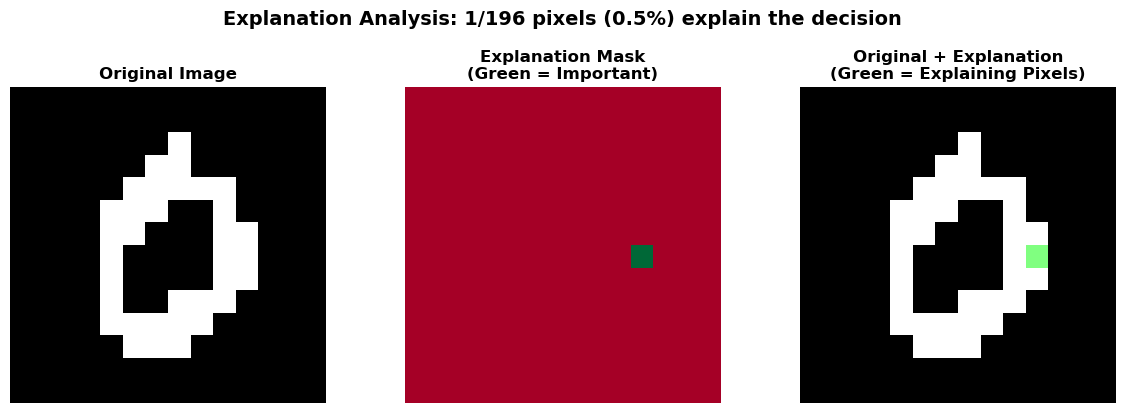

In [36]:
# Visualize the explanation
visualize_explanation(e_complete, best_mask, img_size)


In [37]:
# Greedy search to improve explanation by removing pixels

def greedy_mask_refinement(pc_per_class, priors, data, initial_mask, true_class,
                           max_iterations=100, verbose=True):
    """
    Greedy search to find a better explanation mask by removing pixels.

    Args:
        pc_per_class: Dict of class-specific PCs
        priors: Dict of class priors
        data: Input image [1, features]
        initial_mask: Starting mask [features] (True = observed)
        true_class: The true class label
        max_iterations: Maximum number of refinement steps
        verbose: Print progress

    Returns:
        best_mask: Optimized mask [features]
        best_ep: Best explanation precision achieved
        history: List of (iteration, num_pixels, ep) tuples
    """

    current_mask = initial_mask.clone()
    device = data.device

    # Compute initial EP
    empty_target = torch.zeros(1, current_mask.shape[0], dtype=torch.bool, device=device)
    log_probs = conditional_query_split_pcs(
        pc_per_class, priors, data, empty_target, current_mask.unsqueeze(0),
        class_value=None, class_as_target=True
    )
    probs = torch.exp(log_probs)
    current_ep = probs[0, true_class].item()

    best_mask = current_mask.clone()
    best_ep = current_ep

    history = [(0, current_mask.sum().item(), best_ep)]

    if verbose:
        print("="*70)
        print("GREEDY MASK REFINEMENT")
        print("="*70)
        print(f"Initial: {current_mask.sum().item()} pixels, EP = {current_ep:.4f}")
        print()

    for iteration in range(1, max_iterations + 1):
        # Get indices of currently observed pixels
        observed_indices = torch.where(current_mask)[0]

        if len(observed_indices) == 0:
            if verbose:
                print("No more pixels to remove. Stopping.")
            break

        # Try removing each observed pixel one at a time
        best_improvement = 0
        best_pixel_to_remove = None

        for idx in observed_indices:
            # Create candidate mask by removing this pixel
            candidate_mask = current_mask.clone()
            candidate_mask[idx] = False

            # Evaluate EP with this candidate mask
            log_probs_candidate = conditional_query_split_pcs(
                pc_per_class, priors, data, empty_target, candidate_mask.unsqueeze(0),
                class_value=None, class_as_target=True
            )
            probs_candidate = torch.exp(log_probs_candidate)
            ep_candidate = probs_candidate[0, true_class].item()

            # Check if this is an improvement
            improvement = ep_candidate - current_ep
            if improvement > best_improvement:
                best_improvement = improvement
                best_pixel_to_remove = idx

        # If we found an improvement, apply it
        if best_pixel_to_remove is not None and best_improvement > 0:
            current_mask[best_pixel_to_remove] = False
            current_ep += best_improvement

            if current_ep > best_ep:
                best_ep = current_ep
                best_mask = current_mask.clone()

            history.append((iteration, current_mask.sum().item(), current_ep))

            if verbose:
                print(f"Iter {iteration:3d}: Removed pixel {best_pixel_to_remove.item():3d} | "
                      f"{current_mask.sum().item():3d} pixels | EP = {current_ep:.4f} "
                      f"(+{best_improvement:.4f})")
        else:
            # No improvement found, stop
            if verbose:
                print(f"\nNo improvement found at iteration {iteration}. Stopping.")
            break

    if verbose:
        print()
        print("="*70)
        print(f"FINAL RESULT: {best_mask.sum().item()} pixels, EP = {best_ep:.4f}")
        print(f"Improvement: {best_ep - history[0][2]:.4f}")
        print(f"Reduction: {history[0][1] - best_mask.sum().item()} pixels removed")
        print("="*70)

    return best_mask, best_ep, history


def visualize_refinement_progress(history):
    """Visualize the refinement progress"""
    iterations = [h[0] for h in history]
    num_pixels = [h[1] for h in history]
    eps = [h[2] for h in history]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

    # Plot 1: EP over iterations
    ax1.plot(iterations, eps, 'b-o', linewidth=2, markersize=6)
    ax1.set_xlabel('Iteration', fontsize=12)
    ax1.set_ylabel('Explanation Precision (EP)', fontsize=12)
    ax1.set_title('EP Improvement Over Iterations', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.axhline(y=eps[0], color='r', linestyle='--', label='Initial EP', alpha=0.5)
    ax1.legend()

    # Plot 2: Number of pixels over iterations
    ax2.plot(iterations, num_pixels, 'g-o', linewidth=2, markersize=6)
    ax2.set_xlabel('Iteration', fontsize=12)
    ax2.set_ylabel('Number of Observed Pixels', fontsize=12)
    ax2.set_title('Mask Size Reduction Over Iterations', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"\nSummary:")
    print(f"  Initial: {num_pixels[0]} pixels, EP = {eps[0]:.4f}")
    print(f"  Final:   {num_pixels[-1]} pixels, EP = {eps[-1]:.4f}")
    print(f"  Change:  {num_pixels[-1] - num_pixels[0]} pixels, EP {eps[-1] - eps[0]:+.4f}")


GREEDY MASK REFINEMENT
Initial: 1 pixels, EP = 0.9994


No improvement found at iteration 1. Stopping.

FINAL RESULT: 1 pixels, EP = 0.9994
Improvement: 0.0000
Reduction: 0 pixels removed


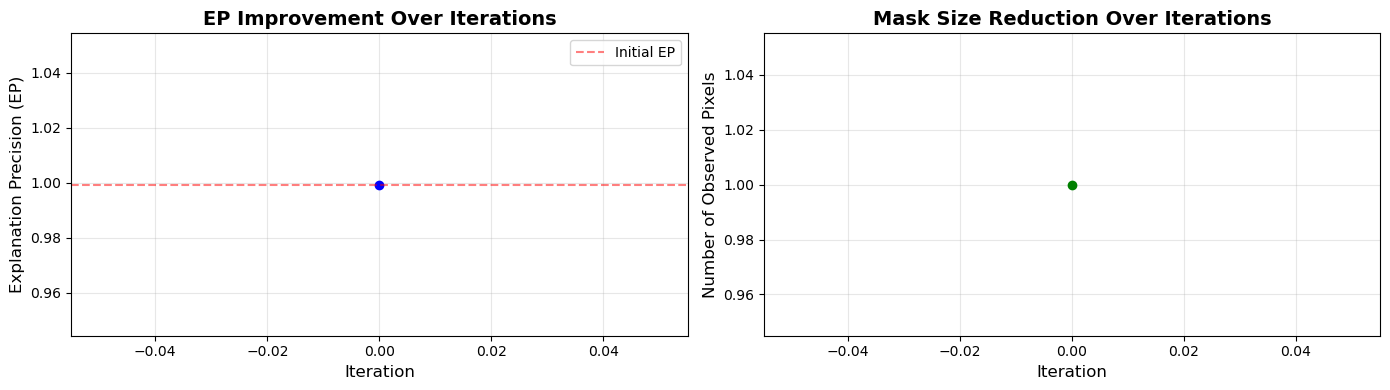


Summary:
  Initial: 1 pixels, EP = 0.9994
  Final:   1 pixels, EP = 0.9994
  Change:  0 pixels, EP +0.0000

COMPARISON: Before vs After Refinement
Before: 1 pixels, EP = 0.9994
After:  1 pixels, EP = 0.9994
Improvement: 0.0000 (0.0% relative)
Pixels removed: 0


In [38]:
# Example usage: Refine the best_mask to improve EP

# Run greedy refinement
refined_mask, refined_ep, history = greedy_mask_refinement(
    pc_per_class=pc_per_class,
    priors=priors,
    data=e_complete,
    initial_mask=best_mask,
    true_class=0,
    max_iterations=100,
    verbose=True
)

# Visualize progress
visualize_refinement_progress(history)

# Compare before and after
print("\n" + "="*70)
print("COMPARISON: Before vs After Refinement")
print("="*70)
print(f"Before: {best_mask.sum().item()} pixels, EP = {history[0][2]:.4f}")
print(f"After:  {refined_mask.sum().item()} pixels, EP = {refined_ep:.4f}")
print(f"Improvement: {refined_ep - history[0][2]:.4f} ({(refined_ep - history[0][2]) / history[0][2] * 100:.1f}% relative)")
print(f"Pixels removed: {best_mask.sum().item() - refined_mask.sum().item()}")

# Update best_mask with refined version
best_mask = refined_mask
best_ep = refined_ep

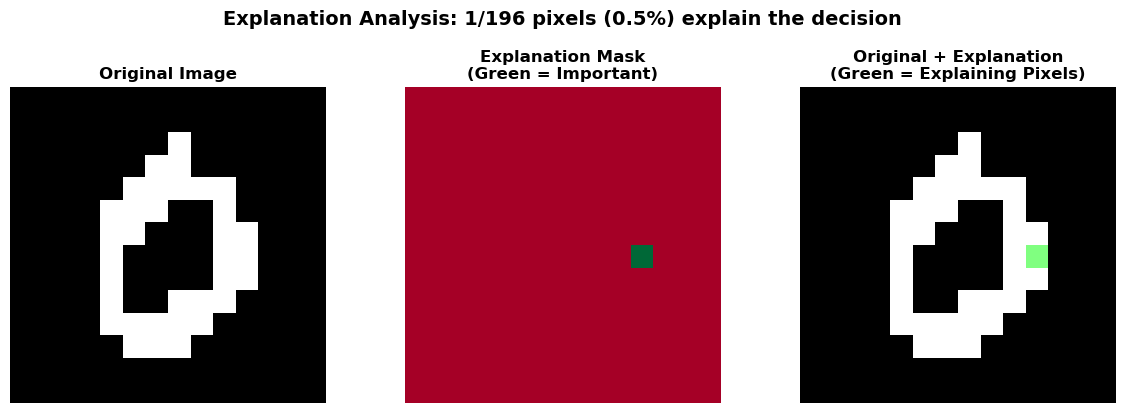

In [39]:
visualize_explanation(e_complete, best_mask, img_size)

### Contrastive explanation

In [40]:
best_cep_mask, best_cep = get_probable_sufficient_explanation(
    e_complete, pc_per_class, priors, class_value=1, mask_obs_ratio=0.5, batch_size=128, delta=0.6
)

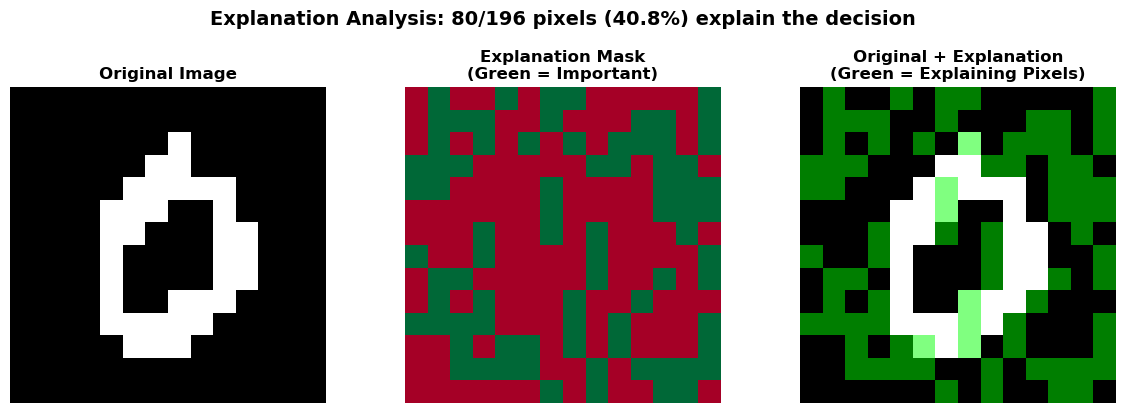

In [41]:
visualize_explanation(e_complete, best_cep_mask, img_size)

In [42]:
# Greedy search for contrastive explanations by ADDING pixels

def greedy_mask_expansion_for_contrastive(pc_per_class, priors, data, initial_mask,
                                         contrastive_class, max_iterations=100,
                                         tolerance=0.01, min_cep=0.5, verbose=True):
    """
    Greedy search to find contrastive explanation by ADDING pixels to the mask.

    Starts with initial_mask (usually empty or minimal) and adds pixels that
    maximize P(contrastive_class | observed).

    Args:
        pc_per_class: Dict of class-specific PCs
        priors: Dict of class priors
        data: Input image [1, features]
        initial_mask: Starting mask [features] (True = observed, usually all False)
        contrastive_class: The class we want to explain (maximize probability for)
        max_iterations: Maximum number of pixels to add
        tolerance: Allow adding pixels that decrease CEP by at most this amount
        min_cep: Stop if CEP falls below this threshold
        verbose: Print progress

    Returns:
        best_mask: Optimized mask [features]
        best_cep: Best contrastive explanation precision achieved
        history: List of (iteration, num_pixels, cep) tuples
    """

    current_mask = initial_mask.clone()
    device = data.device
    num_features = data.shape[1]

    # Compute initial CEP
    empty_target = torch.zeros(1, num_features, dtype=torch.bool, device=device)

    # Get probabilities for the contrastive class
    log_probs = conditional_query_split_pcs(
        pc_per_class, priors, data, empty_target, current_mask.unsqueeze(0),
        class_value=contrastive_class, class_as_target=True
    )
    probs = torch.exp(log_probs)
    current_cep = probs[0].item()

    best_mask = current_mask.clone()
    best_cep = current_cep

    history = [(0, current_mask.sum().item(), best_cep)]

    if verbose:
        print("="*70)
        print("GREEDY MASK EXPANSION FOR CONTRASTIVE EXPLANATIONS (RELAXED)")
        print("="*70)
        print(f"Initial: {current_mask.sum().item()} pixels, CEP = {current_cep:.4f}")
        print(f"Tolerance: {tolerance:.4f}, Min CEP: {min_cep:.4f}")
        print()

    for iteration in range(1, max_iterations + 1):
        # Get indices of currently UNobserved pixels (candidates to add)
        unobserved_indices = torch.where(~current_mask)[0]

        if len(unobserved_indices) == 0:
            if verbose:
                print("All pixels already observed. Stopping.")
            break

        # Try adding each unobserved pixel one at a time
        best_change = -float('inf')
        best_pixel_to_add = None
        best_new_cep = None

        for idx in unobserved_indices:
            # Create candidate mask by adding this pixel
            candidate_mask = current_mask.clone()
            candidate_mask[idx] = True

            # Evaluate CEP with this candidate mask
            log_probs_candidate = conditional_query_split_pcs(
                pc_per_class, priors, data, empty_target, candidate_mask.unsqueeze(0),
                class_value=contrastive_class, class_as_target=True
            )
            probs_candidate = torch.exp(log_probs_candidate)
            cep_candidate = probs_candidate[0].item()

            # Track the best change (can be negative within tolerance)
            change = cep_candidate - current_cep
            if change > best_change:
                best_change = change
                best_pixel_to_add = idx
                best_new_cep = cep_candidate

        # Add pixel if the change is within tolerance and CEP stays above minimum
        if best_pixel_to_add is not None and best_change >= -tolerance and best_new_cep >= min_cep:
            current_mask[best_pixel_to_add] = True
            current_cep = best_new_cep

            if current_cep > best_cep:
                best_cep = current_cep
                best_mask = current_mask.clone()

            history.append((iteration, current_mask.sum().item(), current_cep))

            change_str = f"+{best_change:.4f}" if best_change >= 0 else f"{best_change:.4f}"
            if verbose:
                print(f"Iter {iteration:3d}: Added pixel {best_pixel_to_add.item():3d} | "
                      f"{current_mask.sum().item():3d} pixels | CEP = {current_cep:.4f} "
                      f"({change_str})")
        else:
            # No acceptable pixel found, stop
            if verbose:
                if best_new_cep is not None and best_new_cep < min_cep:
                    print(f"\nBest candidate would drop CEP below {min_cep:.4f}. Stopping.")
                else:
                    print(f"\nNo pixel within tolerance {tolerance:.4f} found. Stopping.")
            break

    if verbose:
        print()
        print("="*70)
        print(f"FINAL RESULT: {current_mask.sum().item()} pixels, CEP = {current_cep:.4f}")
        print(f"Best CEP achieved: {best_cep:.4f}")
        print(f"Pixels added: {current_mask.sum().item() - history[0][1]}")
        print("="*70)

    return current_mask, current_cep, history

In [45]:
# Run greedy refinement
expanded_mask, final_cep, history = greedy_mask_expansion_for_contrastive(
      pc_per_class=pc_per_class,
      priors=priors,
      data=e_complete,
      initial_mask=best_cep_mask,  # Start with the current best mask
      contrastive_class=1,
      max_iterations=100,
      tolerance=0.05,  # Accept up to 5% decrease per pixel
      min_cep=0.8,     # Stop if CEP drops below 80%
      verbose=True
  )

GREEDY MASK EXPANSION FOR CONTRASTIVE EXPLANATIONS (RELAXED)
Initial: 80 pixels, CEP = 0.9015
Tolerance: 0.0500, Min CEP: 0.8000

Iter   1: Added pixel 103 |  81 pixels | CEP = 0.9651 (+0.0636)
Iter   2: Added pixel  36 |  82 pixels | CEP = 0.9860 (+0.0209)
Iter   3: Added pixel  80 |  83 pixels | CEP = 0.9940 (+0.0081)
Iter   4: Added pixel  49 |  84 pixels | CEP = 0.9964 (+0.0023)
Iter   5: Added pixel  47 |  85 pixels | CEP = 0.9977 (+0.0014)
Iter   6: Added pixel  48 |  86 pixels | CEP = 0.9986 (+0.0009)
Iter   7: Added pixel  63 |  87 pixels | CEP = 0.9990 (+0.0004)
Iter   8: Added pixel  52 |  88 pixels | CEP = 0.9992 (+0.0002)
Iter   9: Added pixel  66 |  89 pixels | CEP = 0.9994 (+0.0001)
Iter  10: Added pixel  78 |  90 pixels | CEP = 0.9995 (+0.0001)
Iter  11: Added pixel 131 |  91 pixels | CEP = 0.9995 (+0.0001)
Iter  12: Added pixel 115 |  92 pixels | CEP = 0.9995 (+0.0000)
Iter  13: Added pixel  60 |  93 pixels | CEP = 0.9995 (+0.0000)
Iter  14: Added pixel  95 |  94 pixels

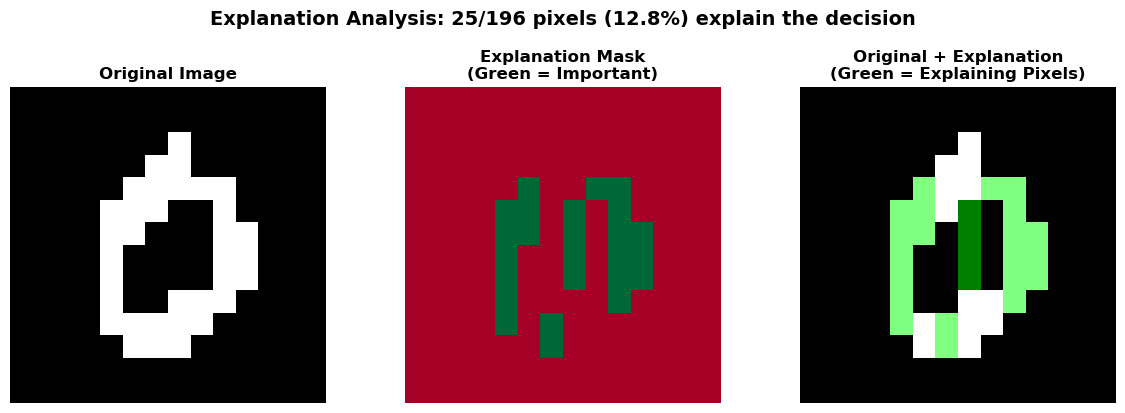

In [46]:
cep_expanded_mask = ~expanded_mask
visualize_explanation(e_complete, cep_expanded_mask, img_size)

In [48]:
# save the best contrastive explanation mask
torch.save(best_cep_mask.cpu(), "models/mnist_binary_small_0_vs_1/mnist_binary_best_contrastive_mask.pt")
print("Best contrastive explanation mask saved to ./examples/models/mnist_binary_small_0_vs_1/mnist_binary_best_contrastive_mask.pt")

Best contrastive explanation mask saved to ./examples/models/mnist_binary_small_0_vs_1/mnist_binary_best_contrastive_mask.pt


In [28]:
# Load mask
best_cep_mask_loaded = torch.load("./examples/models/mnist_binary_small_0_vs_1/mnist_binary_best_contrastive_mask.pt").to(device)

In [49]:
cep_expanded_mask = ~expanded_mask
cep_expanded_mask

tensor([False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False,  True, False, False,  True,  True, False, False, False, False,
        False, False, False, False,  True,  True, False,  True, False,  True,
        False, False, False, False, False, False, False, False,  True,  True,
        False,  True, False,  True,  True, False, False, False, False, False,
        False, False,  True, False, False,  True, False,  True,  True, False,
        False, False, False, False, False, False,  True, False, False,  True,
        False,  True,  True, False, False, False, False, False, 

In [50]:
# apply the contrastive explanation mask to the instance
# so if mask value is True, flip the pixel
e_contrastive = e_complete.clone()
e_contrastive[0, cep_expanded_mask] = 1 - e_contrastive[0, cep_expanded_mask]


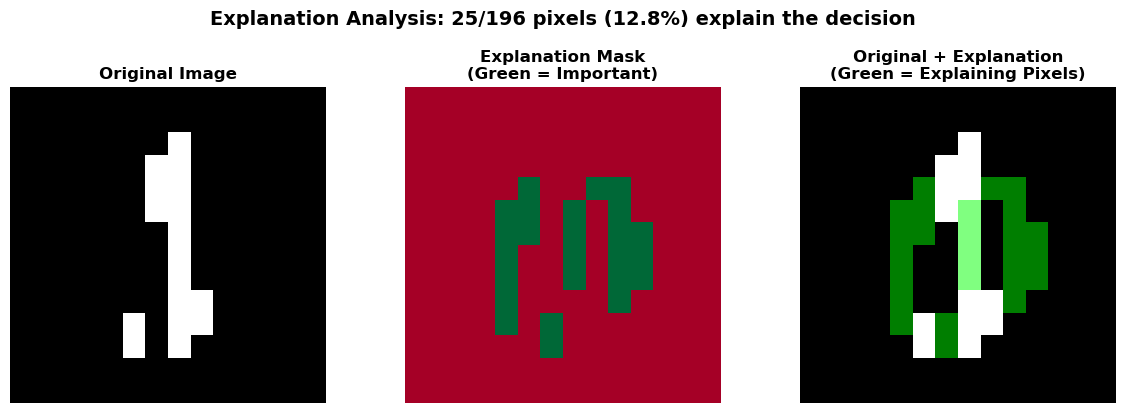

In [51]:
# visualize e_cep_explained
visualize_explanation(e_contrastive, cep_expanded_mask, img_size)

In [52]:
# classification of e_cep_explained
predictions_cep, class_probs_cep = classify_split_pcs(
    pc_per_class, priors, e_contrastive)

print(f"\nClassification with full evidence:")
# print(f"    Predictions:   {predictions_cep.cpu().tolist()}")
print(f"    P(k|x):")
for i in range(1):
    print(f"      Sample {i}: P(k=0)={class_probs_cep[i,0].item():.3f}, P(k=1)={class_probs_cep[i,1].item():.3f}")


Classification with full evidence:
    P(k|x):
      Sample 0: P(k=0)=0.000, P(k=1)=1.000
